# U-net

## Imports

In [16]:
# In[4]:

import os, json, time, hashlib, shutil
from pathlib import Path
from itertools import product
import random  # NEW

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import confusion_matrix, classification_report

# --------------------------
# Reproducible seeding
# --------------------------
SEED = 42  # or any integer you like

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Make cuDNN deterministic (slightly slower but reproducible)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Global seed set to: {SEED}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Global seed set to: 42
device: cuda
GPU: NVIDIA GeForce RTX 2060


## Basic Data Loading

In [17]:
from pathlib import Path
import numpy as np

DATASET_NAME = "ECG5000"
# DATASET_NAME = "NonInvasiveFetalECGThorax1"
# DATASET_NAME = "NonInvasiveFetalECGThorax2"

# Robust path resolution (handles running notebook from different cwd)
HERE = Path().resolve()
DATA_ROOT = HERE / "Data"
if not DATA_ROOT.exists():
    # fallback: search one level up (common if notebook is in subfolder)
    if (HERE.parent / "Data").exists():
        DATA_ROOT = HERE.parent / "Data"

DATA_DIR = DATA_ROOT / DATASET_NAME
assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR}"

train_path = DATA_DIR / f"{DATASET_NAME}_TRAIN.ts"
test_path  = DATA_DIR / f"{DATASET_NAME}_TEST.ts"
assert train_path.exists(), f"Missing: {train_path}"
assert test_path.exists(), f"Missing: {test_path}"

print("Using dataset:", DATASET_NAME)
print("Train file:", train_path)
print("Test file :", test_path)

def load_ucr_ts(ts_path: Path):
    """
    Minimal UCR/UEA .ts loader for univariate classification datasets.
    Returns: X (N, L) float32, y_raw (N,) as original labels (strings)
    """
    X, y = [], []
    in_data = False

    with ts_path.open("r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            low = line.lower()

            # header control
            if low.startswith("@data"):
                in_data = True
                continue
            if not in_data:
                continue

            # data lines:
            # format typically: series_values:label
            # where series_values are comma-separated floats
            if ":" not in line:
                continue

            series_part, label_part = line.rsplit(":", 1)
            label = label_part.strip()
            series_str = series_part.strip()

            # Handle optional parentheses/whitespace
            # Values may be like "0.1,0.2,..." (univariate)
            vals = [v for v in series_str.split(",") if v != ""]
            vals = np.array(vals, dtype=np.float32)

            X.append(vals)
            y.append(label)

    X = np.stack(X, axis=0).astype(np.float32)
    y = np.array(y)

    return X, y

# Load raw labels
X_train_full, y_train_raw = load_ucr_ts(train_path)
X_test, y_test_raw        = load_ucr_ts(test_path)

# Map labels -> 0..K-1 consistently using TRAIN classes
unique_labels = sorted(np.unique(y_train_raw).tolist())
label_to_idx = {lab: i for i, lab in enumerate(unique_labels)}

y_train_full = np.array([label_to_idx[lab] for lab in y_train_raw], dtype=np.int64)
y_test       = np.array([label_to_idx.get(lab, -1) for lab in y_test_raw], dtype=np.int64)

# Sanity check: test labels must all exist in training label set
assert (y_test >= 0).all(), "Found test labels not present in training labels."

classes = unique_labels  # for plotting
num_classes = len(classes)
seq_len = X_train_full.shape[1]

print("Train shape:", X_train_full.shape, "Test shape:", X_test.shape)
print("Classes:", classes, "| num_classes:", num_classes, "| seq_len:", seq_len)


# X_train_full, y_train_full, X_test, y_test already loaded above

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)


Using dataset: ECG5000
Train file: E:\Repos\U-net_cikk\Data\ECG5000\ECG5000_TRAIN.ts
Test file : E:\Repos\U-net_cikk\Data\ECG5000\ECG5000_TEST.ts
Train shape: (500, 140) Test shape: (4500, 140)
Classes: ['1', '2', '3', '4', '5'] | num_classes: 5 | seq_len: 140


## Normalize per sample

In [18]:

def zscore_per_sample(X, eps=1e-8):
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    return (X - mu) / (sd + eps)

X_train = zscore_per_sample(X_train)
X_val   = zscore_per_sample(X_val)
X_test  = zscore_per_sample(X_test)


## Pytorch Datalset/Dataloader

In [19]:
class ECGDataset(Dataset):
    def __init__(self, X, y, augment=False, max_shift=0):
        """
        X: np.array, shape (N, L)
        y: np.array, shape (N,)
        augment: if True, apply random time-shift
        max_shift: maximum absolute shift (in samples). 0 disables shifting.
        """
        self.X = torch.from_numpy(X).unsqueeze(1)  # (N, 1, L)
        self.y = torch.from_numpy(y).long()
        self.augment = augment
        self.max_shift = int(max_shift)

    def __len__(self):
        return len(self.X)

    def _random_shift(self, x):
        """
        x: tensor of shape (C, L)
        Returns: shifted tensor with zero-padding (no wrap-around).
        """
        if self.max_shift <= 0:
            return x

        # Sample shift uniformly in [-max_shift, max_shift]
        shift = torch.randint(-self.max_shift, self.max_shift + 1, (1,)).item()
        if shift == 0:
            return x

        L = x.shape[-1]

        if shift > 0:
            # Shift to the right: new values at the left are zero
            pad = torch.zeros_like(x[..., :shift])
            x_shifted = torch.cat([pad, x[..., :-shift]], dim=-1)
        else:
            # Shift to the left: new values at the right are zero
            s = -shift
            pad = torch.zeros_like(x[..., :s])
            x_shifted = torch.cat([x[..., s:], pad], dim=-1)

        return x_shifted

    def __getitem__(self, i):
        x = self.X[i]
        y = self.y[i]

        if self.augment and self.max_shift > 0:
            x = self._random_shift(x)

        return x, y


# ---- Augmentation settings ----
AUG_TIME_SHIFT = False   # set to True for the augmented experiment
MAX_SHIFT = 5            # in samples, e.g. ±5; tune as desired

train_ds = ECGDataset(
    X_train, y_train,
    augment=AUG_TIME_SHIFT,
    max_shift=MAX_SHIFT,
)
val_ds   = ECGDataset(
    X_val,   y_val,
    augment=False,
    max_shift=0,
)
test_ds  = ECGDataset(
    X_test,  y_test,
    augment=False,
    max_shift=0,
)

# Optional: deterministic shuffling if you have SEED defined
# g = torch.Generator()
# g.manual_seed(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=128,
    shuffle=True,
    drop_last=True,
    # generator=g,
)

val_loader = DataLoader(
    val_ds,
    batch_size=256,
    shuffle=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False,
)


## Train/Eval utils

In [20]:
def train_one_epoch(model, loader, opt, criterion, epoch=0):
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    pbar = tqdm(loader, desc=f"Train {epoch:02d}", leave=False)
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        opt.step()

        bs = xb.size(0)
        total_loss += loss.item() * bs
        correct += (logits.argmax(1) == yb).sum().item()
        n += bs

        pbar.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss/n, correct/n


@torch.no_grad()
def eval_model(model, loader, criterion, epoch=0):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_y = [], []

    pbar = tqdm(loader, desc=f"Eval  {epoch:02d}", leave=False)
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += loss.item() * bs
        preds = logits.argmax(1)

        correct += (preds == yb).sum().item()
        n += bs

        all_preds.append(preds.cpu().numpy())
        all_y.append(yb.cpu().numpy())

        pbar.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss/n, correct/n, np.concatenate(all_y), np.concatenate(all_preds)


def fit(model, train_loader, val_loader, epochs=40, lr=1e-3, weight_decay=1e-4):
    """
    Train with validation:
    - train_loader: training data
    - val_loader:   validation data (used for model selection)
    """
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    best_val_acc, best_state = 0.0, None
    history = []

    for ep in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, criterion, ep)
        val_loss, val_acc, _, _ = eval_model(model, val_loader, criterion, ep)
        history.append((tr_loss, tr_acc, val_loss, val_acc))

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu() for k, v in model.state_dict().items()}

        print(
            f"Epoch {ep:02d}/{epochs-1} | "
            f"train acc {tr_acc:.3f} loss {tr_loss:.4f} | "
            f"val acc {val_acc:.3f} loss {val_loss:.4f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history




## Grad-CAM utils

In [21]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def __call__(self, x, class_idx=None):
        """
        x: (1, 1, L)
        returns cam: (L,)
        """
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(1).item()

        score = logits[:, class_idx]
        score.backward()

        # activations: (1, C, L') gradients: (1, C, L')
        A = self.activations
        dA = self.gradients

        # global-average pool gradients over time to get weights per channel
        weights = dA.mean(dim=-1, keepdim=True)  # (1, C, 1)

        cam = (weights * A).sum(dim=1)  # (1, L')
        cam = F.relu(cam)

        # upsample cam to input length
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-1], mode="linear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, logits.softmax(1).detach().cpu().numpy()

def show_gradcam_1d(model, dataset, idx, class_names=None, target_layer=None):
    model.eval()
    x, y = dataset[idx]
    x_in = x.unsqueeze(0).to(device)

    # pick default layer if not provided
    if target_layer is None:
        # try to use last conv in decoder (dec1) if exists
        target_layer = getattr(model, "dec1", None)
        if target_layer is not None and hasattr(target_layer, "net"):
            # last Conv1d in that block
            target_layer = target_layer.net[3]
        else:
            # fallback: last Conv1d we can find
            convs = [m for m in model.modules() if isinstance(m, torch.nn.Conv1d)]
            target_layer = convs[-1]

    cam_engine = GradCAM1D(model, target_layer)
    cam, pred_idx, probs = cam_engine(x_in)

    sig = x.squeeze().numpy()
    L = sig.shape[0]

    plt.figure(figsize=(10,3))
    plt.plot(sig, label="ECG")
    plt.fill_between(np.arange(L), sig.min(), sig.max(), where=cam>0,
                     alpha=0.3, step="mid")
    plt.title(
        f"Grad-CAM 1D | true={y.item()} pred={pred_idx} "
        + (f"({class_names[pred_idx]})" if class_names else "")
    )
    plt.legend()
    plt.show()

    print("Class probs:", probs[0])


import torch
import torch.nn.functional as F

def match_length(a, b):
    """
    Make tensors a and b have the same last-dimension length by center-cropping the longer one.
    a, b: (N, C, L)
    Returns: (a_matched, b_matched)
    """
    La = a.shape[-1]
    Lb = b.shape[-1]
    if La == Lb:
        return a, b

    if La > Lb:
        diff = La - Lb
        left = diff // 2
        right = diff - left
        a = a[..., left:La-right]
    else:
        diff = Lb - La
        left = diff // 2
        right = diff - left
        b = b[..., left:Lb-right]

    return a, b



## Model 1: Compact 1D U-net

In [22]:
class ConvBlock1D(nn.Module):
    def __init__(self, cin, cout, k=3, p=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(cin, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
            nn.Conv1d(cout, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

class UNet1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        # classifier head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)      # (B, base, L)
        e2 = self.enc2(self.down1(e1))  # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2))  # (B, 4base, L/4)

        d2 = self.up2(e3)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)

## Model 2: 1D U-net + FNO bottleneck

In [23]:
class SpectralConv1d(nn.Module):
    """
    1D spectral conv: FFT -> keep modes -> complex linear map -> iFFT
    """
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        # x: (B, C, L)
        B, C, L = x.shape
        x_ft = torch.fft.rfft(x, dim=-1)  # (B, C, L//2+1)
        out_ft = torch.zeros(B, self.out_channels, x_ft.size(-1), dtype=torch.cfloat, device=x.device)

        m = min(self.modes, x_ft.size(-1))
        out_ft[:, :, :m] = torch.einsum("bci,coi->boi", x_ft[:, :, :m], self.weights[:, :, :m])
        x = torch.fft.irfft(out_ft, n=L, dim=-1)
        return x

class FNOBlock1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.spec = SpectralConv1d(width, width, modes)
        self.pw = nn.Conv1d(width, width, 1)
        self.bn = nn.BatchNorm1d(width)
    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))

class UNetFNO1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.fno = nn.Sequential(*[FNOBlock1d(base*4, modes) for _ in range(fno_layers)])

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)


# Attention U-net

## Model 1: Attention U-net (Attention gate + Attention up block)

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AttentionGate1D(nn.Module):
    """
    Attention gate for 1D skip connections.
    g: gating signal from decoder (coarser)
    x: skip features from encoder (finer)
    returns: attended skip features
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv1d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv1d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv1d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g and x should have same temporal length here
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)  # (B,1,L)
        return x * psi       # broadcast channel-wise


class UpBlockAtt1D(nn.Module):
    """
    Upsample, apply attention gate on skip, concat, then ConvBlock1D.
    """
    def __init__(self, F_g, F_l, F_out):
        super().__init__()
        self.up = nn.ConvTranspose1d(F_g, F_out, kernel_size=2, stride=2)
        self.att = AttentionGate1D(F_g=F_out, F_l=F_l, F_int=F_out//2)
        self.conv = ConvBlock1D(F_out + F_l, F_out)

    def forward(self, g, x_skip):
        g_up = self.up(g)
        # in case of odd lengths, align by trimming/padding
        if g_up.size(-1) != x_skip.size(-1):
            minL = min(g_up.size(-1), x_skip.size(-1))
            g_up = g_up[..., :minL]
            x_skip = x_skip[..., :minL]

        x_att = self.att(g_up, x_skip)
        x = torch.cat([g_up, x_att], dim=1)
        return self.conv(x)


In [25]:
class AttUNet1DClassifier(nn.Module):
    """
    1D Attention U-Net used as feature extractor for classification.
    Attention gates are applied on skip connections.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # Decoder with attention on skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Classification head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)              # (B, base, L)
        e2 = self.enc2(self.down1(e1)) # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2)) # (B, 4base, L/4)

        d2 = self.up2(e3, e2)          # (B, 2base, L/2)
        d1 = self.up1(d2, e1)          # (B, base, L)

        return self.head(d1)


## Model 2: Attention U-net + FNO

In [26]:
class AttUNetFNO1DClassifier(nn.Module):
    """
    1D Attention U-Net with FNO bottleneck for classification.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5,
                 modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # FNO bottleneck (reuse your FNOBlock1d)
        self.fno = nn.Sequential(*[
            FNOBlock1d(base*4, modes) for _ in range(fno_layers)
        ])

        # Decoder with attention skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Classification head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b, e2)
        d1 = self.up1(d2, e1)

        return self.head(d1)


# ResNet1D for baseline

In [27]:

class BasicBlock1D(nn.Module):
    """
    Basic ResNet block for 1D signals:
    Conv1d -> BN -> ReLU -> Conv1d -> BN + skip
    """
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv1d(in_planes, planes, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(planes, planes, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class ResNet1DClassifier(nn.Module):
    """
    1D ResNet baseline for ECG classification.
    Roughly analogous to ResNet-18 in 1D.

    base: controls the width of the network (like your U-Net base channels).
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()

        self.in_planes = base

        # Initial conv: keep it simple and similar scale to U-Net
        self.conv1 = nn.Conv1d(in_ch, base, kernel_size=7,
                               stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(base)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        # ResNet-18 style layer sizes: [base, 2*base, 4*base, 8*base]
        self.layer1 = self._make_layer(BasicBlock1D,  base,      blocks=2, stride=1)
        self.layer2 = self._make_layer(BasicBlock1D,  base * 2,  blocks=2, stride=2)
        self.layer3 = self._make_layer(BasicBlock1D,  base * 4,  blocks=2, stride=2)
        self.layer4 = self._make_layer(BasicBlock1D,  base * 8,  blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(base * 8, num_classes)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_planes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_planes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.in_planes, planes, stride, downsample))
        self.in_planes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.in_planes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        # x: (B, 1, L)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)      # (B, C, 1)
        x = torch.flatten(x, 1)  # (B, C)
        x = self.dropout(x)
        x = self.fc(x)
        return x


# Hyperparameter tuning

Shared:

- base (channels): 16, 32, 48, 64
- lr: 1e-3, 5e-4, 3e-4
- weight_decay: 0, 1e-5, 1e-4, 5e-4
- epochs: fixed (30–60); not a search target unless you want early stopping

Base U-Net-specific:

- dropout: 0.0, 0.1, 0.2, 0.3 (we’ll add it optionally)
- kernel_size: 3 or 5 (optional; more invasive)

FNO-specific:

- modes: 8, 12, 16, 24, 32
- fno_layers: 1, 2, 3

## Evaluation prep

In [28]:
def plot_confusion(cm, class_names, normalize=False, title="Confusion"):
    if normalize:
        cm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(6,5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        xlabel="Predicted",
        ylabel="True",
        title=title
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fmt = ".2f" if normalize else "d"
    thresh = cm.max() * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i,j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i,j] > thresh else "black")
    plt.show()


def eval_and_plot(model, loader, name="Model"):
    crit = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = eval_model(model, loader, crit)
    print(f"{name} acc: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plot_confusion(cm, [str(c) for c in classes], False, f"{name} Confusion (counts)")
    plot_confusion(cm, [str(c) for c in classes], True,  f"{name} Confusion (norm)")

    return acc


## Grid Search

In [29]:
# Resumable Gridsearch (backend) — with training regimes: e40 / e120 / plateau

import hashlib, json, time, copy
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---- Grid definitions ----
grid_shared = {
    "base": [16, 32, 48],
    "lr": [1e-3, 5e-4],
    "weight_decay": [0.0, 1e-4],
    "dropout": [0.0, 0.1, 0.2],
}
grid_fno = {
    "modes": [8, 16, 24],
    "fno_layers": [1, 2],
}

# NEW: training regimes layer
grid_regime = {
    "train_regime": ["e40", "e120", "plateau"]
}


# ---- Model directories ----
MODELS_DIR = Path("models") / DATASET_NAME
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIRS = {
    "base_unet":    MODELS_DIR / "base_unet",
    "unet_fno":     MODELS_DIR / "unet_fno",
    "att_unet":     MODELS_DIR / "att_unet",
    "att_unet_fno": MODELS_DIR / "att_unet_fno",
    "resnet1d":     MODELS_DIR / "resnet1d",
}

# Create base model family dirs only; regime dirs created on-demand
for d in MODEL_DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

LEADERBOARD_PATH = MODELS_DIR / "leaderboard.csv"


# ---- Helpers ----
def expand_grid(g):
    keys, vals = list(g.keys()), list(g.values())
    return [dict(zip(keys, v)) for v in product(*vals)]


def make_config_key(model_type, cfg):
    items = sorted(cfg.items())
    s = model_type + "|" + "|".join([f"{k}={v}" for k, v in items])
    return hashlib.md5(s.encode("utf-8")).hexdigest()


def load_completed_keys():
    if not LEADERBOARD_PATH.exists():
        return set()
    df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
    if "config_key" in df.columns:
        return set(df["config_key"].astype(str))
    completed = set()
    # fallback for earlier CSVs without config_key
    use = ["base","lr","weight_decay","dropout","modes","fno_layers","train_regime"]
    for _, row in df.iterrows():
        cfg = {k: row[k] for k in use if k in row and pd.notna(row[k])}
        completed.add(make_config_key(row["model_type"], cfg))
    return completed


def next_run_dir(model_type, train_regime):
    parent = MODEL_DIRS[model_type] / str(train_regime)
    parent.mkdir(parents=True, exist_ok=True)

    runs = sorted([p for p in parent.glob("run_*") if p.is_dir()])
    rid = len(runs) + 1
    rd = parent / f"run_{rid:03d}"
    rd.mkdir(exist_ok=False)
    return rd, rid


def save_run(model, model_type, cfg, metrics):
    train_regime = cfg.get("train_regime", "e40")

    rd, rid = next_run_dir(model_type, train_regime)

    torch.save(model.state_dict(), rd/"model.pt")
    (rd/"config.json").write_text(json.dumps(cfg, indent=2))
    (rd/"metrics.json").write_text(json.dumps(metrics, indent=2))

    row = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "model_type": model_type,
        "train_regime": str(train_regime),
        "run_id": rid,
        "run_dir": str(rd.as_posix()),  # NEW: explicit path (helps evaluation later)
        "config_key": make_config_key(model_type, cfg),
        **cfg,
        **metrics,
    }

    df = pd.DataFrame([row])
    if LEADERBOARD_PATH.exists():
        df.to_csv(LEADERBOARD_PATH, mode="a", header=False, index=False)
    else:
        df.to_csv(LEADERBOARD_PATH, index=False)


# ---- Build model from config ----
def build_model(model_type, cfg):
    if model_type == "base_unet":
        return UNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "unet_fno":
        return UNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "att_unet":
        return AttUNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "att_unet_fno":
        return AttUNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "resnet1d":
        return ResNet1DClassifier(
            in_ch=1, base=cfg["base"], num_classes=num_classes, dropout=cfg["dropout"]
        )
    raise ValueError(model_type)


# ===========================================================
# Plateau definition & training
# ===========================================================

def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = F.cross_entropy(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)

    return total_loss / max(total, 1), correct / max(total, 1)


@torch.no_grad()
def eval_epoch(model, loader, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = F.cross_entropy(logits, yb)

        total_loss += loss.item() * xb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)

    return total_loss / max(total, 1), correct / max(total, 1)


def fit_regime(
    model,
    train_loader,
    val_loader,
    *,
    lr,
    weight_decay,
    device,
    train_regime,
    # plateau controls:
    min_epochs_plateau=40,
    max_epochs_plateau=300,
    patience=20,
    loss_min_delta=1e-4,
    acc_min_delta=1e-4,
):
    """
    TRAINING REGIMES:
      - e40: train exactly 40 epochs
      - e120: train exactly 120 epochs
      - plateau: train until BOTH val_loss and val_acc plateau (patience),
                 with min_epochs and max_epochs guards.

    Returns:
      model (restored to best checkpoint), history dict, best_info dict
    """

    if train_regime == "e40":
        max_epochs = 40
        do_plateau = False
    elif train_regime == "e120":
        max_epochs = 120
        do_plateau = False
    elif train_regime == "plateau":
        max_epochs = max_epochs_plateau
        do_plateau = True
    else:
        raise ValueError(f"Unknown train_regime: {train_regime}")

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    # best checkpoint selection (primary: val_acc, tie-breaker: val_loss)
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = 0

    # plateau counter counts epochs with NO meaningful improvement in BOTH metrics
    bad_epochs = 0

    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, device)
        va_loss, va_acc = eval_epoch(model, val_loader, device)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        # Improvement definitions:
        acc_improved  = (va_acc  > best_val_acc  + acc_min_delta)
        loss_improved = (va_loss < best_val_loss - loss_min_delta)

        # Save best checkpoint if:
        #  - val_acc improves meaningfully, OR
        #  - val_acc is essentially tied but val_loss improves meaningfully
        if acc_improved or (abs(va_acc - best_val_acc) <= acc_min_delta and loss_improved):
            best_val_acc = va_acc
            best_val_loss = va_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        # Plateau stopping:
        if do_plateau and epoch >= min_epochs_plateau:
            if (not acc_improved) and (not loss_improved):
                bad_epochs += 1
            else:
                bad_epochs = 0

            if bad_epochs >= patience:
                break

    model.load_state_dict(best_state)

    best_info = {
        "best_epoch": int(best_epoch),
        "best_val_acc": float(best_val_acc),
        "best_val_loss": float(best_val_loss),
        "epochs_ran": int(len(history["val_acc"])),
    }
    return model, history, best_info


# ---- Run one config ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def run_one(model_type, cfg):
    model = build_model(model_type, cfg).to(device)

    train_regime = cfg.get("train_regime", "e40")

    model, history, best_info = fit_regime(
        model,
        train_loader,
        val_loader,
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"],
        device=device,
        train_regime=train_regime,
        min_epochs_plateau=40,
        max_epochs_plateau=300,
        patience=20,
        loss_min_delta=1e-4,
        acc_min_delta=1e-4,
    )

    # TEST metrics on best-val checkpoint
    test_loss, test_acc = eval_epoch(model, test_loader, device)

    metrics = {
        "train_regime": str(train_regime),
        "epochs_ran": int(best_info["epochs_ran"]),
        "best_epoch": int(best_info["best_epoch"]),
        "best_val_acc": float(best_info["best_val_acc"]),
        "best_val_loss": float(best_info["best_val_loss"]),
        "val_acc": float(best_info["best_val_acc"]),  # compatibility
        "test_acc": float(test_acc),
        "test_loss": float(test_loss),
        "params_million": sum(p.numel() for p in model.parameters()) / 1e6,
    }

    save_run(model, model_type, cfg, metrics)
    return metrics


# ---- Configs per model type ----
def get_cfgs_for_type(model_type):
    shared = expand_grid(grid_shared)
    regimes = expand_grid(grid_regime)

    def attach_regimes(cfg_list):
        out = []
        for c in cfg_list:
            for r in regimes:
                cc = dict(c)
                cc.update(r)
                out.append(cc)
        return out

    if model_type in ["base_unet", "att_unet", "resnet1d"]:
        return attach_regimes(shared)
    else:
        fno = expand_grid(grid_fno)
        cfgs = []
        for s in shared:
            for f in fno:
                c = dict(s); c.update(f)
                cfgs.append(c)
        return attach_regimes(cfgs)


def count_remaining_configs(model_type):
    done = load_completed_keys()
    cfgs = get_cfgs_for_type(model_type)
    return sum(1 for cfg in cfgs if make_config_key(model_type, cfg) not in done)


# ---- Resumable Gridsearch (widget compatible) ----
def grid_search_resumable(model_type, on_run_done=None):
    done_keys = load_completed_keys()
    cfgs = get_cfgs_for_type(model_type)

    total = len(cfgs)
    ran = 0
    skipped = 0

    print(f"{model_type}: {total} configs")

    for i, cfg in enumerate(cfgs, 1):
        key = make_config_key(model_type, cfg)

        if key in done_keys:
            skipped += 1
            continue

        ran += 1
        print(f"\n[{i}/{total}] RUN {model_type} regime={cfg['train_regime']} cfg={cfg}")
        met = run_one(model_type, cfg)
        print("=>", met)

        if on_run_done is not None:
            on_run_done()

    print(f"{model_type} new runs={ran}, skipped={skipped}")


In [ ]:
# ---- Grid search run script (fixed progress bar + ETA) ----

import time
import pandas as pd
import ipywidgets as widgets
from IPython.display import display

def make_overall_progress(total_remaining):
    bar = widgets.IntProgress(
        value=0, min=0, max=total_remaining,
        description="Gridsearch:",
        bar_style="",
        orientation="horizontal",
        layout=widgets.Layout(width="80%")
    )
    label = widgets.HTML(value=f"<b>0 / {total_remaining}</b> completed")
    sublabel = widgets.HTML(value="Waiting to start…")

    box = widgets.VBox([bar, label, sublabel])
    display(box)

    def update(n_done, text=""):
        bar.value = n_done
        label.value = f"<b>{n_done} / {total_remaining}</b> completed"
        if text:
            sublabel.value = text
    return update


def fmt_seconds(sec):
    sec = int(max(sec, 0))
    h = sec // 3600
    m = (sec % 3600) // 60
    s = sec % 60
    if h > 0: return f"{h}h {m}m {s}s"
    if m > 0: return f"{m}m {s}s"
    return f"{s}s"


def get_last_model_type():
    if not LEADERBOARD_PATH.exists():
        return None
    df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
    if len(df) == 0:
        return None
    return str(df.iloc[-1]["model_type"])


def rotate_model_types(model_types, start_type):
    if start_type is None or start_type not in model_types:
        return model_types
    i = model_types.index(start_type)
    return model_types[i:] + model_types[:i]


def run_all_searches_with_eta():
    base_order = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]

    initial_done = load_completed_keys()

    per_family_remaining = {}
    total_to_run = 0
    for mt in base_order:
        cfgs = get_cfgs_for_type(mt)
        n = sum(
            1
            for cfg in cfgs
            if make_config_key(mt, cfg) not in initial_done
        )
        per_family_remaining[mt] = n
        total_to_run += n

    print("Total configs that will run in this call:", total_to_run)

    if total_to_run == 0:
        print("Nothing left to run – all configs are already completed.")
        df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
        display(df.sort_values("test_acc", ascending=False).head(10))
        print("\nBest per type:")
        display(df.sort_values("test_acc", ascending=False).groupby("model_type").head(1))
        return

    update_overall = make_overall_progress(total_to_run)

    last_type = get_last_model_type()
    model_types = rotate_model_types(base_order, last_type)

    print("Last completed family:", last_type)
    print("Resume order:", model_types)

    done_so_far = 0
    start_time = time.time()

    for mt in model_types:
        rem_this = per_family_remaining.get(mt, 0)

        if rem_this == 0:
            update_overall(
                done_so_far,
                f"<i>Skipping {mt} — no remaining configs in this family</i>"
            )
            continue

        update_overall(
            done_so_far,
            f"<i>Running {mt} — {rem_this} configs left in this family</i>"
        )

        def callback():
            nonlocal done_so_far
            done_so_far += 1

            elapsed = time.time() - start_time
            avg_per_run = elapsed / done_so_far if done_so_far > 0 else 0.0
            remaining = total_to_run - done_so_far
            eta_sec = remaining * avg_per_run

            update_overall(
                done_so_far,
                (
                    f"<i>Running {mt}…</i><br>"
                    f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                    f"Avg/run: <b>{fmt_seconds(avg_per_run)}</b> | "
                    f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
                )
            )

        grid_search_resumable(mt, on_run_done=callback)

    elapsed_total = time.time() - start_time
    update_overall(
        done_so_far,
        f"<b>All searches complete ✅</b><br>Total time: <b>{fmt_seconds(elapsed_total)}</b>"
    )

    df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
    display(df.sort_values("test_acc", ascending=False).head(10))

    print("\nBest per type:")
    display(df.sort_values("test_acc", ascending=False).groupby("model_type").head(1))


# Call this in the notebook:
run_all_searches_with_eta()


Total configs that will run in this call: 1620


Last completed family: None
Resume order: ['base_unet', 'unet_fno', 'att_unet', 'att_unet_fno', 'resnet1d']
base_unet: 108 configs

[1/108] RUN base_unet regime=e40 cfg={'base': 16, 'lr': 0.001, 'weight_decay': 0.0, 'dropout': 0.0, 'train_regime': 'e40'}
=> {'train_regime': 'e40', 'epochs_ran': 40, 'best_epoch': 35, 'best_val_acc': 0.94, 'best_val_loss': 0.3447614908218384, 'val_acc': 0.94, 'test_acc': 0.9282222222222222, 'test_loss': 0.37603742451137967, 'params_million': 0.041589}

[2/108] RUN base_unet regime=e120 cfg={'base': 16, 'lr': 0.001, 'weight_decay': 0.0, 'dropout': 0.0, 'train_regime': 'e120'}
=> {'train_regime': 'e120', 'epochs_ran': 120, 'best_epoch': 111, 'best_val_acc': 0.94, 'best_val_loss': 0.2407069355249405, 'val_acc': 0.94, 'test_acc': 0.9271111111111111, 'test_loss': 0.26863963243696426, 'params_million': 0.041589}

[3/108] RUN base_unet regime=plateau cfg={'base': 16, 'lr': 0.001, 'weight_decay': 0.0, 'dropout': 0.0, 'train_regime': 'plateau'}
=> {'train_regime'

## Results (so far)

### Stats for the runs

In [17]:
# Evaluate ALL trained models (NO confusion matrices)

import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, balanced_accuracy_score
import tqdm.auto as tq

def eval_single_model_for_stats(model, test_loader, device="cuda"):
    """
    Evaluate a single model on the test set and compute:
    - accuracy
    - macro-F1 (over all classes)
    - balanced accuracy
    """
    model.eval()
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(1)
            y_true_all.append(yb.cpu().numpy())
            y_pred_all.append(preds.cpu().numpy())

    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)

    # Explicitly specify labels and zero_division for stability
    label_ids = np.arange(num_classes)

    acc      = float((y_true == y_pred).mean())
    macro_f1 = float(
        f1_score(
            y_true, y_pred,
            labels=label_ids,
            average="macro",
            zero_division=0,
        )
    )
    bal_acc  = float(
        balanced_accuracy_score(
            y_true, y_pred
        )
    )

    return acc, macro_f1, bal_acc


def evaluate_all_models_stats():
    # IMPORTANT: dataset-scoped models directory
    MODELS_DIR = Path("models") / DATASET_NAME

    families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
    rows = []

    # Count models robustly
    total_models = 0
    for f in families:
        fam_dir = MODELS_DIR / f
        if fam_dir.exists():
            total_models += len([d for d in fam_dir.glob("run_*") if d.is_dir()])

    print("Models directory:", MODELS_DIR.resolve())
    print("Found total trained models:", total_models)

    if total_models == 0:
        raise RuntimeError(
            f"No trained runs found under {MODELS_DIR}. "
            f"Expected structure like: models/{DATASET_NAME}/base_unet/run_XXX/"
        )

    pbar = tq.tqdm(total=total_models, desc=f"Evaluating models ({DATASET_NAME})")

    for family in families:
        fam_dir = MODELS_DIR / family
        if not fam_dir.exists():
            continue

        runs = sorted([d for d in fam_dir.glob("run_*") if d.is_dir()])

        for r in runs:
            config_path  = r / "config.json"
            metrics_path = r / "metrics.json"
            weights_path = r / "model.pt"

            if not (config_path.exists() and weights_path.exists()):
                pbar.update(1)
                continue

            # Load config
            with open(config_path, "r") as f:
                cfg = json.load(f)

            # Load model
            model = build_model(family, cfg)
            state = torch.load(weights_path, map_location=device)
            model.load_state_dict(state)
            model.to(device)

            # Evaluate on TEST set
            acc, macro_f1, bal_acc = eval_single_model_for_stats(
                model, test_loader, device
            )

            row = {
                "family": family,
                "run_id": r.name,
                **cfg,
                "test_acc": acc,
                "macro_f1": macro_f1,
                "balanced_acc": bal_acc,
            }

            # Add extra metrics from metrics.json
            if metrics_path.exists():
                with open(metrics_path, "r") as f:
                    saved_metrics = json.load(f)

                if "params_million" in saved_metrics:
                    row["params_million"] = saved_metrics["params_million"]
                if "val_acc" in saved_metrics:
                    row["val_acc"] = saved_metrics["val_acc"]

            rows.append(row)
            pbar.update(1)

    pbar.close()

    df = pd.DataFrame(rows)

    out_path = MODELS_DIR / "eval_stats.csv"
    df.to_csv(out_path, index=False)
    print("Saved:", out_path)

    return df.sort_values("macro_f1", ascending=False)



df_stats = evaluate_all_models_stats()
df_stats


Models directory: E:\Repos\U-net_cikk\models\NonInvasiveFetalECGThorax1
Found total trained models: 540


Evaluating models (NonInvasiveFetalECGThorax1):   0%|          | 0/540 [00:00<?, ?it/s]

C:\Users\Hontika\AppData\Local\Temp\ipykernel_34804\3393436263.py:99: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(weights_path, map_location=device)
C:\

Saved: models\NonInvasiveFetalECGThorax1\eval_stats.csv


,family,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,balanced_acc,params_million,val_acc,modes,fno_layers
535,resnet1d,run_032,48,0.0005,0.0000,0.1,0.946056,0.943487,0.944246,2.180250,0.938889,NaN,NaN
522,resnet1d,run_019,32,0.0005,0.0000,0.0,0.945038,0.943348,0.944608,0.974282,0.947222,NaN,NaN
537,resnet1d,run_034,48,0.0005,0.0001,0.0,0.944020,0.941593,0.942538,2.180250,0.944444,NaN,NaN
531,resnet1d,run_028,48,0.0010,0.0001,0.0,0.943511,0.941316,0.942160,2.180250,0.933333,NaN,NaN
523,resnet1d,run_020,32,0.0005,0.0000,0.1,0.943003,0.940447,0.942416,0.974282,0.938889,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
92,unet_fno,run_057,16,0.0005,0.0001,0.0,0.179644,0.104185,0.183891,0.112042,0.177778,16.0,1.0
8,base_unet,run_009,16,0.0005,0.0000,0.2,0.179644,0.102150,0.181821,0.042218,0.188889,NaN,NaN
106,unet_fno,run_071,16,0.0005,0.0001,0.2,0.196438,0.097985,0.195443,0.144810,0.183333,24.0,1.0
84,unet_fno,run_049,16,0.0005,0.0000,0.2,0.185751,0.097586,0.192975,0.079274,0.213889,8.0,1.0


In [18]:
# Create a CSV with top 5 models per family (dataset-scoped)

import pandas as pd
from pathlib import Path

def make_top5_per_family():
    MODELS_DIR = Path("models") / DATASET_NAME
    stats_path = MODELS_DIR / "eval_stats.csv"

    if not stats_path.exists():
        raise FileNotFoundError(f"eval_stats.csv not found at: {stats_path}")

    df = pd.read_csv(stats_path)

    families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
    top_rows = []

    for fam in families:
        sub = df[df["family"] == fam]
        if sub.empty:
            print(f"Warning: No runs found for {fam}")
            continue

        top5 = sub.sort_values("macro_f1", ascending=False).head(5)
        top_rows.append(top5)

    if not top_rows:
        raise RuntimeError(f"No families had any models to select in {stats_path}")

    out_df = pd.concat(top_rows, ignore_index=True)

    out_path = MODELS_DIR / "top5_per_family.csv"
    out_df.to_csv(out_path, index=False)
    print("Saved:", out_path)

    return out_df.sort_values(["family", "macro_f1"], ascending=[True, False])


df_top5 = make_top5_per_family()
df_top5


Saved: models\NonInvasiveFetalECGThorax1\top5_per_family.csv


,family,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,balanced_acc,params_million,val_acc,modes,fno_layers
10,att_unet,run_030,48,0.0010,0.0001,0.2,0.762850,0.742920,0.766157,0.381288,0.783333,NaN,NaN
11,att_unet,run_026,48,0.0010,0.0000,0.1,0.764377,0.741597,0.764802,0.381288,0.769444,NaN,NaN
12,att_unet,run_025,48,0.0010,0.0000,0.0,0.751654,0.732305,0.754642,0.381288,0.777778,NaN,NaN
13,att_unet,run_029,48,0.0010,0.0001,0.1,0.747583,0.729710,0.753915,0.381288,0.788889,NaN,NaN
14,att_unet,run_028,48,0.0010,0.0001,0.0,0.747074,0.725781,0.755659,0.381288,0.788889,NaN,NaN
15,att_unet_fno,run_184,48,0.0005,0.0000,0.0,0.923155,0.918930,0.922122,1.635816,0.911111,16.0,2.0
16,att_unet_fno,run_186,48,0.0005,0.0000,0.0,0.919084,0.917201,0.919934,2.225640,0.911111,24.0,2.0
17,att_unet_fno,run_213,48,0.0005,0.0001,0.2,0.917557,0.914666,0.915498,1.008552,0.919444,16.0,1.0
18,att_unet_fno,run_114,32,0.0005,0.0000,0.0,0.915013,0.913086,0.916266,0.990720,0.911111,24.0,2.0
19,att_unet_fno,run_203,48,0.0005,0.0001,0.0,0.916539,0.910738,0.913701,1.303464,0.913889,24.0,1.0


In [21]:
import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
df = pd.read_csv(MODELS_DIR / "eval_stats.csv")

# Example: pick the best ResNet1D run
best_resnet = df[df["family"] == "resnet1d"].sort_values("macro_f1", ascending=False).iloc[0]
p_ref = best_resnet["params_million"]

# Filter other families to those within ±10% of ResNet params
tol = 0.10  # 10%
mask = (df["params_million"] >= p_ref * (1 - tol)) & \
       (df["params_million"] <= p_ref * (1 + tol))

df_close = df[mask]

families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
best_param_matched = []
for fam in families:
    sub = df_close[df_close["family"] == fam]
    if len(sub):
        best_param_matched.append(sub.sort_values("macro_f1", ascending=False).iloc[0])

best_param_matched = pd.DataFrame(best_param_matched)
best_param_matched


,family,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,balanced_acc,params_million,val_acc,modes,fno_layers
185,unet_fno,run_150,48,0.0010,0.0,0.0,0.809669,0.791898,0.812449,2.21361,0.847222,24.0,2.0
473,att_unet_fno,run_186,48,0.0005,0.0,0.0,0.919084,0.917201,0.919934,2.22564,0.911111,24.0,2.0
535,resnet1d,run_032,48,0.0005,0.0,0.1,0.946056,0.943487,0.944246,2.18025,0.938889,NaN,NaN


### Plots for evaluation

In [22]:
from pathlib import Path
import pandas as pd

MODELS_DIR = Path("models") / DATASET_NAME
eval_df = pd.read_csv(MODELS_DIR / "eval_stats.csv")
top5_df = pd.read_csv(MODELS_DIR / "top5_per_family.csv")

eval_df.head(), top5_df.head()


(      family   run_id  base     lr  weight_decay  dropout  test_acc  macro_f1  \
 0  base_unet  run_001    16  0.001        0.0000      0.0  0.452417  0.391239   
 1  base_unet  run_002    16  0.001        0.0000      0.1  0.391858  0.327056   
 2  base_unet  run_003    16  0.001        0.0000      0.2  0.322137  0.252902   
 3  base_unet  run_004    16  0.001        0.0001      0.0  0.426463  0.379657   
 4  base_unet  run_005    16  0.001        0.0001      0.1  0.222901  0.148652   
 
    balanced_acc  params_million   val_acc  modes  fno_layers  
 0      0.460485        0.042218  0.427778    NaN         NaN  
 1      0.398462        0.042218  0.388889    NaN         NaN  
 2      0.335681        0.042218  0.336111    NaN         NaN  
 3      0.436984        0.042218  0.425000    NaN         NaN  
 4      0.234082        0.042218  0.258333    NaN         NaN  ,
       family   run_id  base     lr  weight_decay  dropout  test_acc  macro_f1  \
 0  base_unet  run_027    48  0.001    

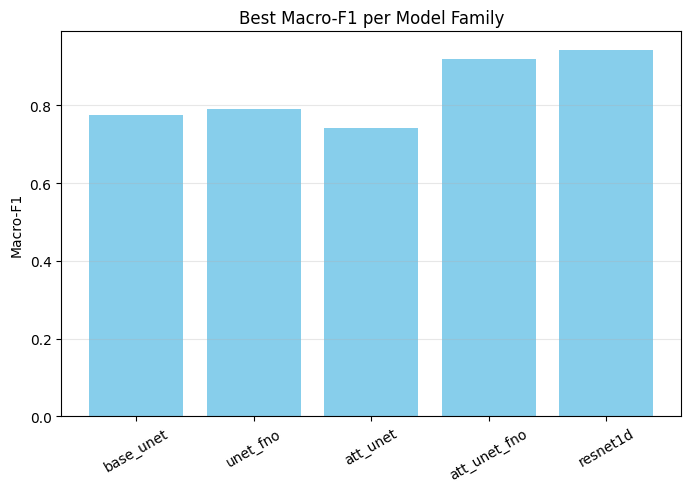

In [23]:
# Best Macro-F1 per family

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(Path("models") / DATASET_NAME / "eval_stats.csv")

families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]

best_rows = []
for fam in families:
    best = df[df["family"] == fam].sort_values("macro_f1", ascending=False).head(1)
    best_rows.append(best)

best_df = pd.concat(best_rows)

plt.figure(figsize=(8,5))
plt.bar(best_df["family"], best_df["macro_f1"], color="skyblue")
plt.ylabel("Macro-F1")
plt.title("Best Macro-F1 per Model Family")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()


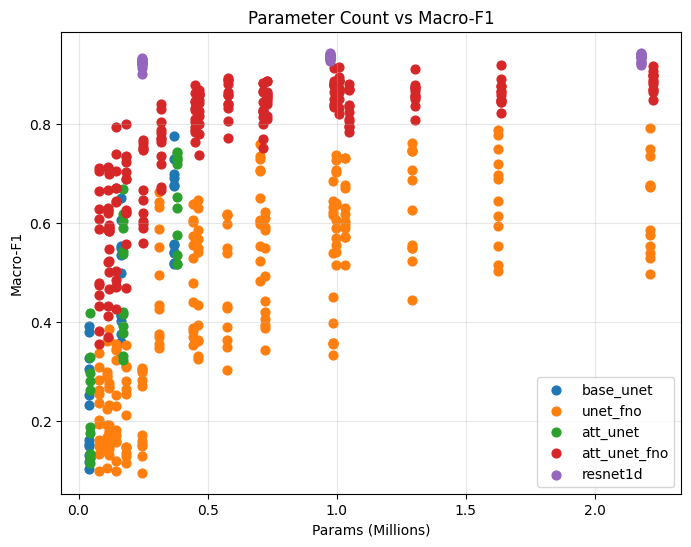

In [24]:
# Params vs Macro-F1

plt.figure(figsize=(8,6))

for fam in families:
    sub = df[df["family"] == fam]
    plt.scatter(sub["params_million"], sub["macro_f1"], label=fam, s=40)

plt.xlabel("Params (Millions)")
plt.ylabel("Macro-F1")
plt.title("Parameter Count vs Macro-F1")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


C:\Users\Hontika\AppData\Local\Temp\ipykernel_34804\3060266276.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=top5, x="family", y="macro_f1", palette="Set2")


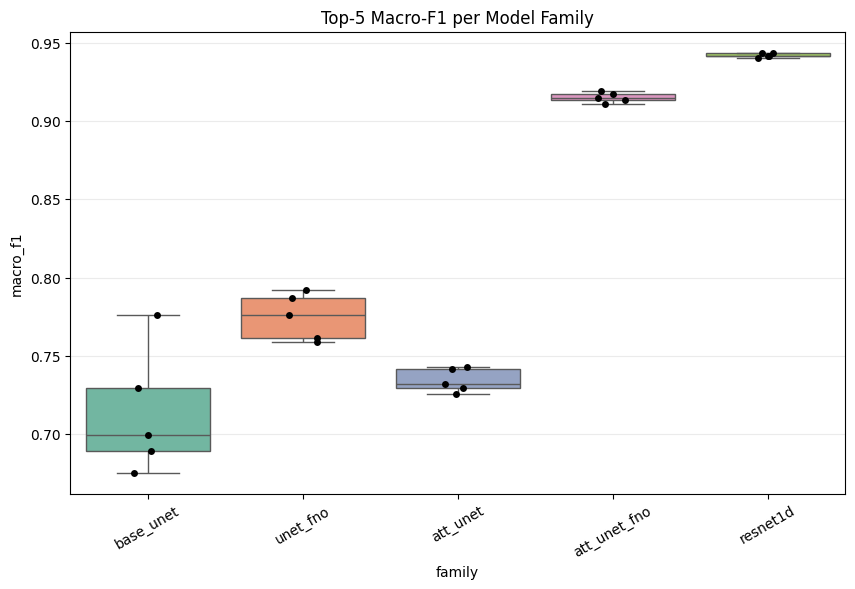

In [26]:
# Top-5 Macro-F1 Distribution per Family

import seaborn as sns

top5 = pd.read_csv(Path("models") / DATASET_NAME / "top5_per_family.csv")

plt.figure(figsize=(10,6))
sns.boxplot(data=top5, x="family", y="macro_f1", palette="Set2")
sns.stripplot(data=top5, x="family", y="macro_f1", color="black")
plt.title("Top-5 Macro-F1 per Model Family")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.25)
plt.show()


In [31]:
# ===========================================================
# Export all evaluation figures to JPGs into figs/
#   - confusion_grid.jpg
#   - per_class_f1.jpg
#   - top5_boxplot.jpg
#   - params_vs_macroF1.jpg
# ===========================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix, balanced_accuracy_score

# ---------- Paths & setup ----------
MODELS_DIR = Path("models") / DATASET_NAME
EVAL_STATS_PATH = MODELS_DIR / "eval_stats.csv"
TOP5_PATH = MODELS_DIR / "top5_per_family.csv"
FIG_DIR = Path("figs") / DATASET_NAME
FIG_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
pretty_names = {
    "base_unet":     "Base U-Net",
    "unet_fno":      "U-Net + FNO",
    "att_unet":      "Attention U-Net",
    "att_unet_fno":  "Attention U-Net + FNO",
    "resnet1d":      "ResNet1D",
}

# ---------- Helper: build model from config ----------
def build_model_for_eval(family, cfg):
    """
    Build correct model instance for a family using saved config.
    Assumes these classes already exist in the notebook:
      - UNet1DClassifier
      - UNetFNO1DClassifier
      - AttUNet1DClassifier
      - AttUNetFNO1DClassifier
      - ResNet1DClassifier
    And global num_classes is defined.
    """
    base = int(cfg.get("base", 32))
    dropout = float(cfg.get("dropout", 0.0))
    modes = int(cfg.get("modes", 16)) if "modes" in cfg else 16
    fno_layers = int(cfg.get("fno_layers", 2)) if "fno_layers" in cfg else 2

    if family == "base_unet":
        return UNet1DClassifier(in_ch=1, base=base, num_classes=num_classes, dropout=dropout)
    elif family == "unet_fno":
        return UNetFNO1DClassifier(
            in_ch=1, base=base, num_classes=num_classes,
            modes=modes, fno_layers=fno_layers, dropout=dropout
        )
    elif family == "att_unet":
        return AttUNet1DClassifier(in_ch=1, base=base, num_classes=num_classes, dropout=dropout)
    elif family == "att_unet_fno":
        return AttUNetFNO1DClassifier(
            in_ch=1, base=base, num_classes=num_classes,
            modes=modes, fno_layers=fno_layers, dropout=dropout
        )
    elif family == "resnet1d":
        return ResNet1DClassifier(in_ch=1, base=base, num_classes=num_classes, dropout=dropout)
    else:
        raise ValueError(f"Unknown family: {family}")


# ---------- Helper: load best model per family ----------
def load_best_model(family, metric="macro_f1"):
    df = pd.read_csv(EVAL_STATS_PATH)
    sub = df[df["family"] == family]
    if sub.empty:
        raise ValueError(f"No rows found for family '{family}' in eval_stats.csv")

    best_row = sub.sort_values(metric, ascending=False).iloc[0]
    run_id = best_row["run_id"]
    run_dir = MODELS_DIR / family / run_id

    cfg_path = run_dir / "config.json"
    weights_path = run_dir / "model.pt"

    with open(cfg_path, "r") as f:
        cfg = json.load(f)

    model = build_model_for_eval(family, cfg)
    state = torch.load(weights_path, map_location=device)
    model.load_state_dict(state)
    model.to(device)
    model.eval()

    return model, best_row


# ---------- Helper: evaluate model (for confusion, stats) ----------
def evaluate_model_full(model, loader, classes):
    """
    Evaluate model on the given loader (test_loader in our use)
    and return confusion matrix + metrics in a dict.
    """
    model.eval()
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(1)
            y_true_all.append(yb.cpu().numpy())
            y_pred_all.append(preds.cpu().numpy())

    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)

    label_ids = np.arange(len(classes))

    cm = confusion_matrix(y_true, y_pred, labels=label_ids)
    acc = float((y_true == y_pred).mean())
    macro_f1 = float(
        f1_score(
            y_true, y_pred,
            labels=label_ids,
            average="macro",
            zero_division=0,
        )
    )
    bal_acc = float(balanced_accuracy_score(y_true, y_pred))

    return {
        "cm": cm,
        "acc": acc,
        "macro_f1": macro_f1,
        "balanced_acc": bal_acc,
        "y_true": y_true,
        "y_pred": y_pred,
    }


# ===========================================================
# 1) Confusion matrices (one image per model family, clearer)
# ===========================================================
print("Exporting confusion matrices (clear version)...")

df_eval = pd.read_csv(EVAL_STATS_PATH)
fams_available = [f for f in families if (df_eval["family"] == f).any()]

if not fams_available:
    print("No families found in eval_stats.csv, skipping confusion matrices.")
else:
    for fam in fams_available:
        print(f"  - {fam}")

        model, best_row = load_best_model(fam, metric="macro_f1")
        res = evaluate_model_full(model, test_loader, classes)
        cm = res["cm"]
        K = len(classes)

        # ---- Scale figure size with number of classes ----
        # 0.55 inch per class is a good readability baseline.
        side = max(9.0, min(24.0, 0.55 * K))
        fig, ax = plt.subplots(figsize=(side, side))

        im = ax.imshow(cm, cmap="Blues", interpolation="nearest")

        # ---- Title ----
        ax.set_title(
            f"{pretty_names.get(fam, fam)} — Confusion Matrix\n"
            f"macro-F1={res['macro_f1']:.3f} | acc={res['acc']:.3f} | bal-acc={res['balanced_acc']:.3f}",
            fontsize=16, pad=18
        )

        # ---- Ticks/labels ----
        ax.set_xticks(np.arange(K))
        ax.set_yticks(np.arange(K))

        # Smaller fonts for many classes
        tick_fs = 12 if K <= 10 else 10 if K <= 20 else 8

        ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=tick_fs)
        ax.set_yticklabels(classes, fontsize=tick_fs)

        ax.set_xlabel("Predicted", fontsize=14, labelpad=10)
        ax.set_ylabel("True", fontsize=14, labelpad=10)

        # ---- Gridlines to help reading cells ----
        ax.set_xticks(np.arange(-.5, K, 1), minor=True)
        ax.set_yticks(np.arange(-.5, K, 1), minor=True)
        ax.grid(which="minor", linestyle="-", linewidth=0.4, alpha=0.25)
        ax.tick_params(which="minor", bottom=False, left=False)

        # ---- Annotate only for small/medium K ----
        if K <= 12:
            thresh = cm.max() * 0.6 if cm.max() > 0 else 0.0
            for (r, c), val in np.ndenumerate(cm):
                ax.text(
                    c, r, str(val),
                    ha="center", va="center",
                    fontsize=10,
                    color="white" if val > thresh else "black"
                )

        # ---- Colorbar on the right, with readable size ----
        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        cbar.ax.set_ylabel("Count", rotation=90, fontsize=14)
        cbar.ax.tick_params(labelsize=12)

        # Keep aspect square and spacing clean
        ax.set_aspect("equal")
        plt.tight_layout()

        out_path = FIG_DIR / f"confusion_{fam}.jpg"
        plt.savefig(out_path, dpi=400, bbox_inches="tight")  # higher DPI
        plt.close(fig)

print("Done exporting clear per-family confusion matrices.")


# ===========================================================
# 2) Per-class F1 comparison (split into chunks of 5 classes)
# ===========================================================
print("Exporting per-class F1 comparison (chunked)...")

def compute_per_class_f1(model):
    model.eval()
    y_true_all, y_pred_all = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(1)
            y_true_all.append(yb.cpu().numpy())
            y_pred_all.append(preds.cpu().numpy())
    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    label_ids = np.arange(len(classes))
    return f1_score(y_true, y_pred, labels=label_ids, average=None, zero_division=0)

# Determine available families (same logic)
df_eval = pd.read_csv(EVAL_STATS_PATH)
fams_available = [f for f in families if (df_eval["family"] == f).any()]

per_class_f1_dict = {}
for fam in fams_available:
    try:
        model, _ = load_best_model(fam, metric="macro_f1")
        per_class_f1_dict[fam] = compute_per_class_f1(model)
    except Exception as e:
        print(f"Skipping {fam} in per_class_f1: {e}")

if not per_class_f1_dict:
    print("No models available to plot per-class F1.")
else:
    K = len(classes)
    chunk_size = 5

    fam_list = list(per_class_f1_dict.keys())

    for start in range(0, K, chunk_size):
        end = min(start + chunk_size, K)
        chunk_classes = classes[start:end]

        x = np.arange(end - start)
        # width depends on number of models, but keep it reasonable
        width = min(0.18, 0.8 / max(1, len(fam_list)))

        fig, ax = plt.subplots(figsize=(10, 5))

        for i, fam in enumerate(fam_list):
            vals = per_class_f1_dict[fam][start:end]
            ax.bar(
                x + i * width,
                vals,
                width,
                label=pretty_names.get(fam, fam),
            )

        ax.set_xticks(x + width * (len(fam_list) - 1) / 2)
        ax.set_xticklabels(chunk_classes, rotation=45, ha="right")
        ax.set_ylim(0, 1.05)
        ax.set_ylabel("F1 Score")
        ax.set_title(f"Per-Class F1 (Classes {start+1}–{end})")
        ax.grid(axis="y", alpha=0.3)
        ax.legend(fontsize=9)

        plt.tight_layout()
        out_path = FIG_DIR / f"per_class_f1_{start+1:02d}_{end:02d}.jpg"
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
        plt.close(fig)

print("Done exporting chunked per-class F1 plots.")

# ===========================================================
# 3) Top-5 per family boxplot
# ===========================================================
print("Exporting top5_boxplot.jpg .")

if TOP5_PATH.exists():
    top5 = pd.read_csv(TOP5_PATH)

    fig, ax = plt.subplots(figsize=(10, 6))
    top5.boxplot(column="macro_f1", by="family", ax=ax)
    ax.set_title("Top-5 Macro-F1 per Model Family")
    ax.set_ylabel("Macro F1")
    plt.suptitle("")

    plt.tight_layout()
    plt.savefig(FIG_DIR / "top5_boxplot.jpg", dpi=300, bbox_inches="tight")
    plt.close(fig)
else:
    print("Warning: top5_per_family.csv not found, skipping top5_boxplot.jpg")


# ===========================================================
# 4) Params vs macro-F1 scatter
# ===========================================================
print("Exporting params_vs_macroF1.jpg .")

df_stats = pd.read_csv(EVAL_STATS_PATH)

fig, ax = plt.subplots(figsize=(9, 6))

for fam in families:
    sub = df_stats[df_stats["family"] == fam]
    if sub.empty:
        continue
    ax.scatter(
        sub["params_million"],
        sub["macro_f1"],
        label=pretty_names.get(fam, fam),
        alpha=0.7
    )

ax.set_xlabel("Params (Millions)")
ax.set_ylabel("Macro F1")
ax.set_title("Parameter Count vs Macro-F1")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "params_vs_macroF1.jpg", dpi=300, bbox_inches="tight")
plt.close(fig)

print("✅ All plots exported to 'figs/' as JPG files.")


Using device: cuda
Exporting confusion matrices (clear version)...
  - base_unet


C:\Users\Hontika\AppData\Local\Temp\ipykernel_34804\1863806578.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(weights_path, map_location=device)


  - unet_fno


C:\Users\Hontika\AppData\Local\Temp\ipykernel_34804\1863806578.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(weights_path, map_location=device)


  - att_unet


...

  - resnet1d


C:\Users\Hontika\AppData\Local\Temp\ipykernel_34804\1863806578.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(weights_path, map_location=device)


Done exporting clear per-family confusion matrices.
Exporting per-class F1 comparison (chunked)...


C:\Users\Hontika\AppData\Local\Temp\ipykernel_34804\1863806578.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(weights_path, map_location=device)
C:\

Done exporting chunked per-class F1 plots.
Exporting top5_boxplot.jpg .
Exporting params_vs_macroF1.jpg .
✅ All plots exported to 'figs/' as JPG files.


In [29]:
import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
eval_stats_path = MODELS_DIR / "eval_stats.csv"

df = pd.read_csv(eval_stats_path)

families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
pretty = {
    "base_unet":    "U-Net",
    "unet_fno":     "U-Net + FNO",
    "att_unet":     "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d":     "ResNet1D",
}

print("% LaTeX rows for Table: Best configuration per model family")
for fam in families:
    sub = df[df["family"] == fam]
    if sub.empty:
        continue
    best = sub.sort_values("macro_f1", ascending=False).iloc[0]

    family_name = pretty[fam]
    macro  = best["macro_f1"]
    bal    = best["balanced_acc"]
    acc    = best["test_acc"]
    params = best.get("params_million", float("nan"))
    run_id = best["run_id"]
    base   = best["base"]

    row = (
        f"{family_name:23} & "
        f"{macro:.3f} & {bal:.3f} & {acc:.3f} & "
        f"{params:.2f} & \\texttt{{{run_id}}} & {int(base)} \\\\"
    )
    print(row)


% LaTeX rows for Table: Best configuration per model family
U-Net                   & 0.776 & 0.796 & 0.793 & 0.37 & \texttt{run_027} & 48 \\
U-Net + FNO             & 0.792 & 0.812 & 0.810 & 2.21 & \texttt{run_150} & 48 \\
Attention U-Net         & 0.743 & 0.766 & 0.763 & 0.38 & \texttt{run_030} & 48 \\
Attention U-Net + FNO   & 0.919 & 0.922 & 0.923 & 1.64 & \texttt{run_184} & 48 \\
ResNet1D                & 0.943 & 0.944 & 0.946 & 2.18 & \texttt{run_032} & 48 \\


In [20]:
!python -m nbconvert --to script Pipeline.ipynb


[NbConvertApp] Converting notebook Pipeline.ipynb to script
[NbConvertApp] Writing 57472 bytes to Pipeline.py
